## BRT
1. Build presences/absences
2. Fit one full model + vessel-type-specific models
3. Extract relative importance of each driver, partial dependence plots
5. Tune hyperparameters

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from sklearn.inspection import PartialDependenceDisplay

from brt_modeling import (
    build_presence_absence, debug_presence_absence, sample_rasters,
    get_raster_paths, rebalance_1to1, run_model,
)
from config import PERIODS

gear_types = ["TRAWLERS", "DRIFTING_LONGLINES", "SQUID_JIGGER", "TUNA_PURSE_SEINES", None] # None = all gear types
period = "2023_2025"
gear_type = gear_types[2]

df_gaps = pd.read_csv(f"data/processed/gaps_{period}_filtered.csv")
start, end = PERIODS[period]
# paper keeps gaps that start and end inside the period; drop_duplicates guards against the gear merge duplicating events
df_gaps = df_gaps[(pd.to_datetime(df_gaps['start'], utc=True) >= pd.Timestamp(start, tz='UTC')) &
                  (pd.to_datetime(df_gaps['end'], utc=True) < pd.Timestamp(end, tz='UTC') + pd.Timedelta(days=1))].drop_duplicates('id')

df_fishing = pd.read_csv(f"data/raw/fishing_gridded_{period}.csv")
df_fishing

/tmp/ipykernel_44924/1133562109.py:21: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  (pd.to_datetime(df_gaps['end'], utc=True) < pd.Timestamp(end, tz='UTC') + pd.Timedelta(days=1))].drop_duplicates('id')


,lat,lon,flag,gear_type,hours
0,-77.8,-177.6,NZL,set_longlines,2.000000
1,-77.8,-177.5,NZL,set_longlines,0.816667
2,-77.8,-177.2,NZL,set_longlines,0.684444
3,-77.8,-177.1,NZL,set_longlines,0.998333
4,-77.8,-177.0,NZL,set_longlines,1.000278
...,...,...,...,...,...
4508661,89.6,100.7,RUS,inconclusive,0.900000
4508662,89.6,101.1,RUS,inconclusive,1.017500
4508663,89.6,101.8,RUS,inconclusive,1.033055
4508664,89.6,102.0,RUS,inconclusive,0.949445


In [6]:
raster_paths = get_raster_paths(period)
feature_cols = list(raster_paths.keys())

# Run model per geartype and save results

Number of presence cells vs absence rows:  2083 143401
[TRAWLERS] 2083 presences, 2083 absences
Explained deviance: 56.04%  AUC: 0.852 ± 0.014  TSS: 0.562 ± 0.029


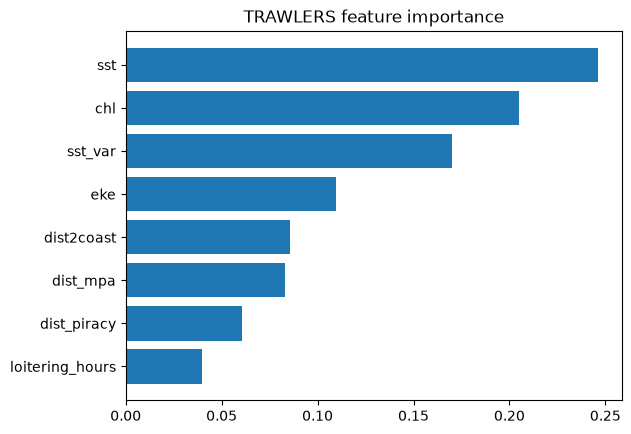

Saved metrics + importance for 'TRAWLERS' -> model_results/2023_2025
Number of presence cells vs absence rows:  17346 491764
[DRIFTING_LONGLINES] 17346 presences, 17346 absences
Explained deviance: 15.63%  AUC: 0.725 ± 0.005  TSS: 0.339 ± 0.010


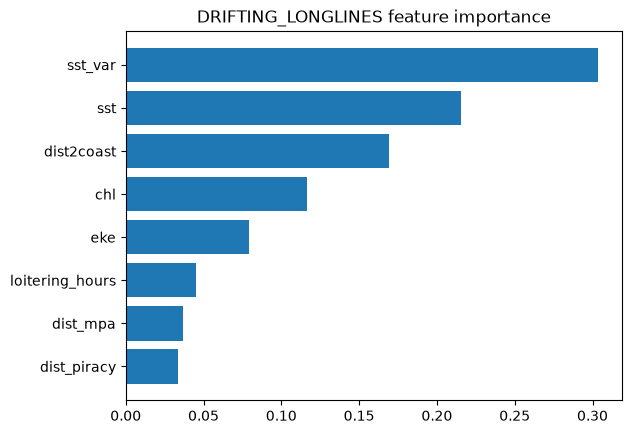

Saved metrics + importance for 'DRIFTING_LONGLINES' -> model_results/2023_2025
Number of presence cells vs absence rows:  3523 18830
[SQUID_JIGGER] 3523 presences, 3523 absences
Explained deviance: 58.40%  AUC: 0.876 ± 0.010  TSS: 0.570 ± 0.022


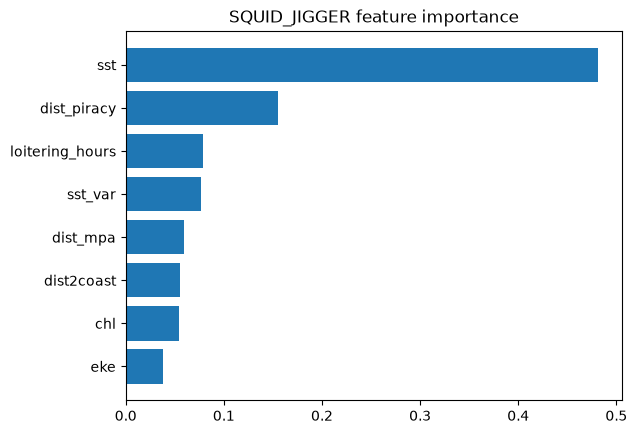

Saved metrics + importance for 'SQUID_JIGGER' -> model_results/2023_2025
Number of presence cells vs absence rows:  6487 47789
[TUNA_PURSE_SEINES] 6487 presences, 6487 absences
Explained deviance: 16.79%  AUC: 0.711 ± 0.009  TSS: 0.318 ± 0.016


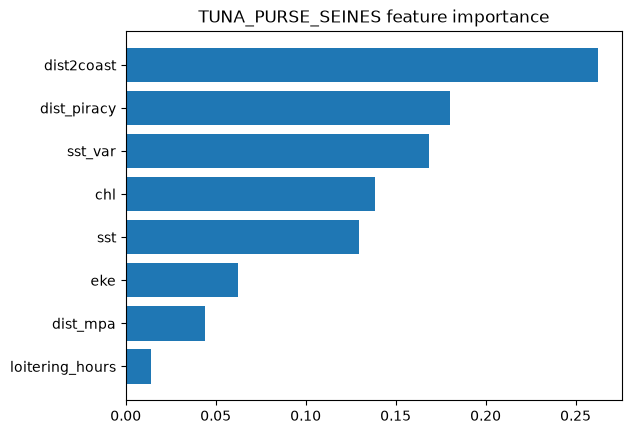

Saved metrics + importance for 'TUNA_PURSE_SEINES' -> model_results/2023_2025
Number of presence cells vs absence rows:  37922 1057598
[full] 37922 presences, 37922 absences
Explained deviance: 20.56%  AUC: 0.735 ± 0.005  TSS: 0.363 ± 0.010


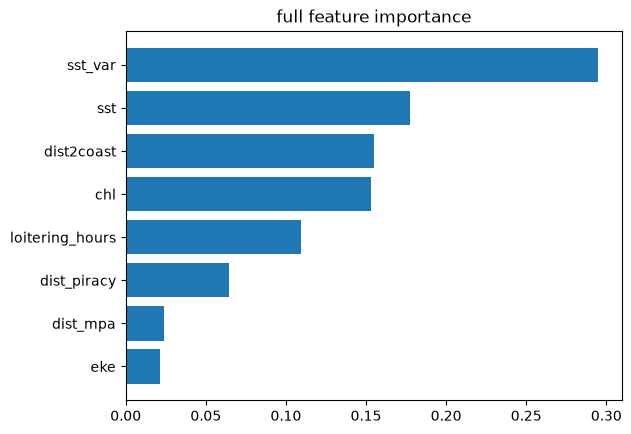

Saved metrics + importance for 'full' -> model_results/2023_2025


In [7]:
#model_df, model, metrics = run_model(df_gaps, df_fishing, feature_cols, raster_paths, gear_type=gear_type)
for gear_type in gear_types:
    model_df, model, metrics = run_model(df_gaps, df_fishing, feature_cols, raster_paths, gear_type=gear_type, outdir=f"model_results/{period}")
    
